<a href="https://colab.research.google.com/github/Parth-22k/ML-Lab/blob/main/Exp3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


First 5 rows of dataset:
   Index  Height(Inches)  Weight(Pounds)
0      1        65.78331        112.9925
1      2        71.51521        136.4873
2      3        69.39874        153.0269
3      4        68.21660        142.3354
4      5        67.78781        144.2971

Actual Weight:
[125.4542 117.1655 137.3184 149.4447 151.0695 116.9994 138.1787 127.621
 120.7514 144.2537]

Predicted Weight:
[124.05064103 120.5205476  133.52992135 131.12784975 133.67692831
 117.35763997 132.4468385  125.74483702 114.0286508  138.54647463]

Mean Squared Error: 102.20432251335677


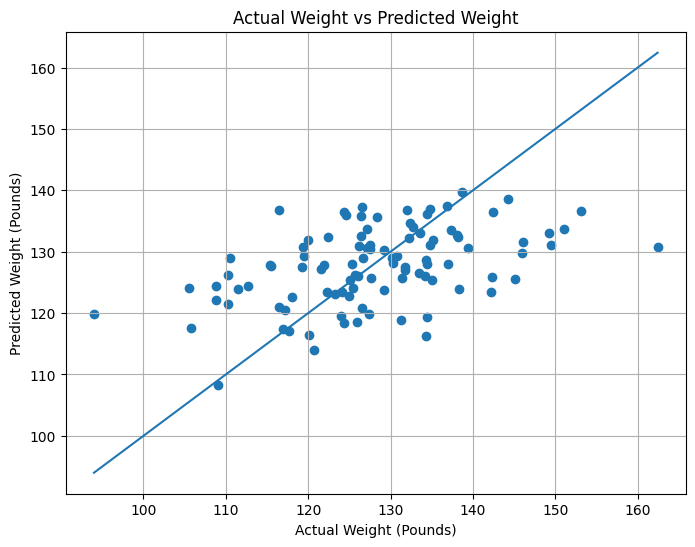

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------
# Load Dataset
# --------------------------------

df = pd.read_csv("/content/drive/MyDrive/ML/SOCR-HeightWeight.csv")

df = df.iloc[:500] #Keep 500 rows first

print("First 5 rows of dataset:")
print(df.head())


# --------------------------------
# Remove Index
# --------------------------------

df = df.drop(columns=["Index"])


# --------------------------------
# Separate Input and Output
# --------------------------------

X = df["Height(Inches)"].values
y = df["Weight(Pounds)"].values


# --------------------------------
# Convert X into 2D
# --------------------------------

X = X.reshape(-1, 1)


# --------------------------------
# Train-Test Split
# --------------------------------

train_size = int(0.8 * len(X))

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]


# --------------------------------
# Feature Scaling
# --------------------------------

X_mean = np.mean(X_train)
X_std = np.std(X_train)

X_train = (X_train - X_mean) / X_std
X_test = (X_test - X_mean) / X_std


# --------------------------------
# Add Bias
# --------------------------------

X_train = np.c_[np.ones(len(X_train)), X_train]
X_test = np.c_[np.ones(len(X_test)), X_test]


# --------------------------------
# Initialize Weight and Bias
# --------------------------------

weights = np.zeros(2)

learning_rate = 0.01
epochs = 1000


# --------------------------------
# Gradient Descent
# --------------------------------

for i in range(epochs):

    # Prediction
    y_pred = np.dot(X_train, weights)

    # Error
    error = y_pred - y_train

    # Gradient
    gradient = (2 / len(X_train)) * np.dot(X_train.T, error)

    # Update weights
    weights = weights - learning_rate * gradient


# --------------------------------
# Test Prediction
# --------------------------------

y_pred_test = np.dot(X_test, weights)


# --------------------------------
# Display Results
# --------------------------------

print("\nActual Weight:")
print(y_test[:10])

print("\nPredicted Weight:")
print(y_pred_test[:10])


# --------------------------------
# Mean Squared Error
# --------------------------------

mse = np.mean((y_test - y_pred_test) ** 2)

print("\nMean Squared Error:", mse)


# --------------------------------
# Actual vs Predicted Graph
# --------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_test)

minimum = min(y_test.min(), y_pred_test.min())
maximum = max(y_test.max(), y_pred_test.max())

# Perfect prediction line
plt.plot(
    [minimum, maximum],
    [minimum, maximum]
)

plt.xlabel("Actual Weight (Pounds)")
plt.ylabel("Predicted Weight (Pounds)")
plt.title("Actual Weight vs Predicted Weight")

plt.grid(True)
plt.show()